# EcoHome Energy Advisor - Database Setup

In this notebook, you'll set up the database for the EcoHome Energy Advisor. The database will store:
- Energy usage data (consumption, device types, costs)
- Solar generation data (production, weather conditions)

## Learning Objectives
- Create SQLite database with proper schema
- Populate database with sample data
- Query data for analysis
- Understand database design for energy management


## 1. Import Required Libraries


In [1]:
# Import the necessary libraries
from datetime import datetime, timedelta
import random

from models.energy import DatabaseManager

from models.energy import Base

# Fixed seed: the same data every time the notebook runs on the same day.
random.seed(42)


## 2. Initialize Database Manager


In [2]:
# Create a DatabaseManager instance
# Initialize it with the path "data/energy_data.db"
db_manager = DatabaseManager("data/energy_data.db")


## 3. Create Database Tables


In [3]:
# Create the database tables
# Start from empty tables: create_tables() alone appends, so running this notebook twice
# would double every record and every total the agent reports.
Base.metadata.drop_all(bind=db_manager.engine)
db_manager.create_tables()

Database tables created at data/energy_data.db


## 4. Generate Sample Energy Usage Data


In [4]:
# Generate sample energy usage data for the past 30 days
# Include different device types: EV, HVAC, appliances
# Use realistic consumption patterns (higher during peak hours)

# Device types and their typical consumption patterns
device_types = {
    'EV': {'base_kwh': 10, 'variation': 5, 'peak_hours': [18, 19, 20, 21]},
    'HVAC': {'base_kwh': 2, 'variation': 1, 'peak_hours': [12, 13, 14, 15, 16, 17]},
    'appliance': {'base_kwh': 1.5, 'variation': 0.5, 'peak_hours': [19, 20, 21, 22]}
}

# Generate data for the past 30 days
today = datetime.now().replace(hour=0, minute=0, second=0, microsecond=0)
start_date = today - timedelta(days=30)   # 30 full days plus today up to the current hour
records_created = 0

for day in range(31):
    current_date = start_date + timedelta(days=day)
    
    for hour in range(24):
        timestamp = current_date.replace(hour=hour, minute=0, second=0, microsecond=0)
        if timestamp > datetime.now():
            break   # no records in the future
        
        # Generate usage for each device type
        for device_type, config in device_types.items():
            # Base consumption with variation
            base_consumption = config['base_kwh']
            variation = random.uniform(-config['variation'], config['variation'])
            
            # Peak hour multiplier
            peak_multiplier = 1.5 if hour in config['peak_hours'] else 0.8
            
            consumption = max(0, (base_consumption + variation) * peak_multiplier)
            
            # Calculate cost (simplified pricing)
            price_per_kwh = 0.15 if hour in config['peak_hours'] else 0.10
            cost = consumption * price_per_kwh
            
            # Device names
            device_names = {
                'EV': 'Tesla Model 3',
                'HVAC': 'Main AC Unit',
                'appliance': random.choice(['Dishwasher', 'Washing Machine', 'Dryer'])
            }
            
            # Add record to database
            db_manager.add_usage_record(
                timestamp=timestamp,
                consumption_kwh=consumption,
                device_type=device_type,
                device_name=device_names[device_type],
                cost_usd=cost
            )
            records_created += 1

print(f"Created {records_created} energy usage records")


Created 2205 energy usage records


## 5. Generate Sample Solar Generation Data


In [5]:
# Generate sample solar generation data
# Consider weather patterns, time of day, and seasonal variations

# Weather conditions and their impact on solar generation
weather_conditions = {
    'sunny': {'multiplier': 1.0, 'probability': 0.4},
    'partly_cloudy': {'multiplier': 0.6, 'probability': 0.3},
    'cloudy': {'multiplier': 0.3, 'probability': 0.2},
    'rainy': {'multiplier': 0.1, 'probability': 0.1}
}

# Generate solar generation data for the same period
today = datetime.now().replace(hour=0, minute=0, second=0, microsecond=0)
start_date = today - timedelta(days=30)   # 30 full days plus today up to the current hour
generation_records = 0

for day in range(31):
    current_date = start_date + timedelta(days=day)
    
    # Select weather condition for the day
    weather_choice = random.choices(
        list(weather_conditions.keys()),
        weights=[weather_conditions[w]['probability'] for w in weather_conditions.keys()]
    )[0]
    weather_multiplier = weather_conditions[weather_choice]['multiplier']
    
    for hour in range(24):
        timestamp = current_date.replace(hour=hour, minute=0, second=0, microsecond=0)
        if timestamp > datetime.now():
            break   # no records in the future
        
        # Solar generation only during daylight hours (6 AM to 6 PM)
        if 6 <= hour <= 18:
            # Base generation curve (peak at noon)
            hour_factor = 1 - abs(hour - 12) / 6  # Peak at hour 12
            base_generation = 5.0 * hour_factor  # Max 5 kWh at peak
            
            # Apply weather multiplier
            generation = base_generation * weather_multiplier
            
            # Add some random variation
            generation *= random.uniform(0.8, 1.2)
            generation = max(0, generation)
            
            # Calculate temperature (affects solar efficiency)
            base_temp = 20 + random.uniform(-5, 5)
            temp_factor = 1.0 if 15 <= base_temp <= 35 else 0.9
            
            # Solar irradiance calculation
            irradiance = 800 * hour_factor * weather_multiplier if generation > 0 else 0
            
            # Add record to database
            db_manager.add_generation_record(
                timestamp=timestamp,
                generation_kwh=generation,
                weather_condition=weather_choice,
                temperature_c=base_temp * temp_factor,
                solar_irradiance=irradiance
            )
            generation_records += 1

print(f"Created {generation_records} solar generation records")


Created 399 solar generation records


## 6. Query and Analyze Data


In [6]:
# Query the data to verify it was inserted correctly
# Show total consumption by device type
# Show daily solar generation patterns
# Calculate some basic statistics

# Get recent data for analysis
recent_usage = db_manager.get_recent_usage(24)  # Last 24 hours
recent_generation = db_manager.get_recent_generation(24)

print("=== Energy Usage Analysis ===")
print(f"Total records in last 24 hours: {len(recent_usage)}")

# Group by device type
device_consumption = {}
for record in recent_usage:
    device = record.device_type or 'unknown'
    if device not in device_consumption:
        device_consumption[device] = {'kwh': 0, 'cost': 0, 'records': 0}
    device_consumption[device]['kwh'] += record.consumption_kwh
    device_consumption[device]['cost'] += record.cost_usd or 0
    device_consumption[device]['records'] += 1

print("\nConsumption by device type:")
for device, data in device_consumption.items():
    print(f"  {device}: {data['kwh']:.2f} kWh, ${data['cost']:.2f}, {data['records']} records")

print(f"\n=== Solar Generation Analysis ===")
print(f"Total generation records in last 24 hours: {len(recent_generation)}")

total_generation = sum(r.generation_kwh for r in recent_generation)
print(f"Total generation: {total_generation:.2f} kWh")

# Weather breakdown
weather_breakdown = {}
for record in recent_generation:
    weather = record.weather_condition or 'unknown'
    if weather not in weather_breakdown:
        weather_breakdown[weather] = {'kwh': 0, 'records': 0}
    weather_breakdown[weather]['kwh'] += record.generation_kwh
    weather_breakdown[weather]['records'] += 1

print("\nGeneration by weather condition:")
for weather, data in weather_breakdown.items():
    print(f"  {weather}: {data['kwh']:.2f} kWh, {data['records']} records")


=== Energy Usage Analysis ===
Total records in last 24 hours: 72

Consumption by device type:
  EV: 235.96 kWh, $27.34, 24 records
  HVAC: 48.03 kWh, $5.74, 24 records
  appliance: 32.84 kWh, $3.75, 24 records

=== Solar Generation Analysis ===
Total generation records in last 24 hours: 13
Total generation: 16.29 kWh

Generation by weather condition:
  cloudy: 1.52 kWh, 4 records
  partly_cloudy: 14.77 kWh, 9 records


## 6b. Confirm the required tables

The rubric names the tables by their model classes, `EnergyUsage` and `SolarGeneration`. In the SQLite file they are stored as `energy_usage` and `solar_generation` (each class sets `__tablename__`). This cell lists both and counts their rows.

In [7]:
import sqlalchemy
from models.energy import EnergyUsage, SolarGeneration

tables = sqlalchemy.inspect(db_manager.engine).get_table_names()
print("Tables in data/energy_data.db:", tables)
session = db_manager.get_session()
for model in (EnergyUsage, SolarGeneration):
    print(f"  {model.__name__:<16} -> table {model.__tablename__!r:<20} rows: {session.query(model).count()}")
session.close()
assert {"energy_usage", "solar_generation"} <= set(tables), "required tables missing"

Tables in data/energy_data.db: ['energy_usage', 'solar_generation']
  EnergyUsage      -> table 'energy_usage'       rows: 2205
  SolarGeneration  -> table 'solar_generation'   rows: 399


## 7. Test Database Tools


In [8]:
# Test the database query functions from tools.py
# Import and test: query_energy_usage, query_solar_generation, get_recent_energy_summary

from tools import query_energy_usage, query_solar_generation, get_recent_energy_summary

# Test querying data for the last 7 days
end_date = datetime.now().strftime("%Y-%m-%d")
start_date = (datetime.now() - timedelta(days=7)).strftime("%Y-%m-%d")

print("=== Testing Database Tools ===")
print(f"Querying data from {start_date} to {end_date}")

# Test energy usage query
usage_data = query_energy_usage.invoke(
    input={
        "start_date": start_date, 
        "end_date": end_date,
    }
)
print(f"\nEnergy Usage Query Results:")
print(f"  Total records: {usage_data['total_records']}")
print(f"  Total consumption: {usage_data['total_consumption_kwh']} kWh")
print(f"  Total cost: ${usage_data['total_cost_usd']}")

# Test solar generation query
generation_data = query_solar_generation.invoke(
    input={
        "start_date": start_date, 
        "end_date": end_date,
    }
)
print(f"\nSolar Generation Query Results:")
print(f"  Total records: {generation_data['total_records']}")
print(f"  Total generation: {generation_data['total_generation_kwh']} kWh")
print(f"  Average daily: {generation_data['average_daily_generation']} kWh")

# Test recent energy summary
summary = get_recent_energy_summary.invoke(
    input={
        "hours": 24
    }
)
print(f"\nRecent Energy Summary:")
print(f"  Usage: {summary['usage']['total_consumption_kwh']} kWh, ${summary['usage']['total_cost_usd']}")
print(f"  Generation: {summary['generation']['total_generation_kwh']} kWh")
print(f"  Weather: {summary['generation']['average_weather']}")


=== Testing Database Tools ===
Querying data from 2026-11-12 to 2026-11-19

Energy Usage Query Results:
  Total records: 549
  Total consumption: 2248.02 kWh
  Total cost: $255.38

Solar Generation Query Results:
  Total records: 100
  Total generation: 156.82 kWh
  Average daily: 19.6 kWh

Recent Energy Summary:
  Usage: 316.83 kWh, $36.82
  Generation: 16.29 kWh
  Weather: partly_cloudy


## 8. Usage and generation patterns

Daily energy use by device type against daily solar generation, and the average hour-of-day profile. These are the patterns the advisor reasons about.

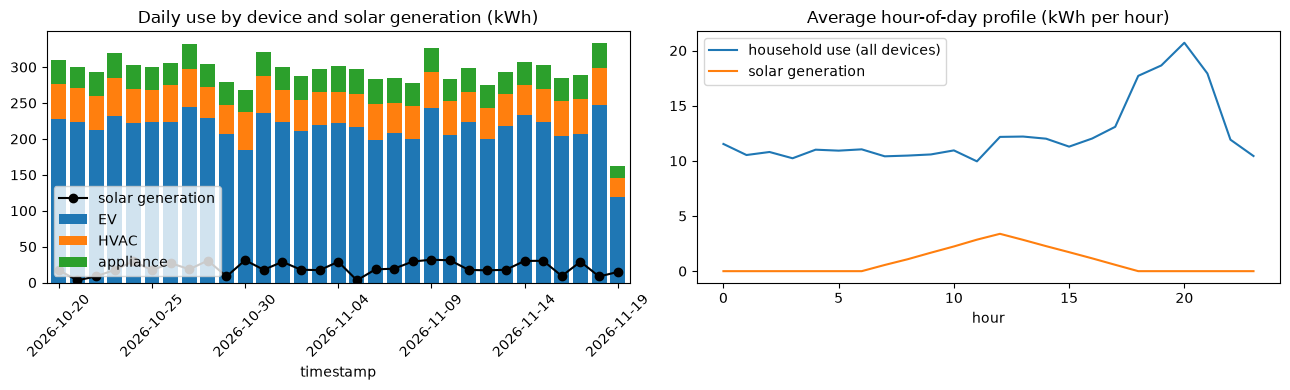

device_type
EV           6691.5
HVAC         1430.0
appliance     999.9


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

session = db_manager.get_session()
usage = pd.read_sql("SELECT timestamp, consumption_kwh, device_type, cost_usd FROM energy_usage", db_manager.engine, parse_dates=["timestamp"])
solar = pd.read_sql("SELECT timestamp, generation_kwh FROM solar_generation", db_manager.engine, parse_dates=["timestamp"])
session.close()

daily = usage.groupby([usage.timestamp.dt.date, "device_type"]).consumption_kwh.sum().unstack()
daily_solar = solar.groupby(solar.timestamp.dt.date).generation_kwh.sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
daily.plot(kind="bar", stacked=True, ax=axes[0], width=0.8)
daily_solar.plot(ax=axes[0], color="black", marker="o", label="solar generation", use_index=False)
axes[0].set_title("Daily use by device and solar generation (kWh)")
axes[0].set_xticks(range(0, len(daily), 5)); axes[0].set_xticklabels([str(d) for d in daily.index[::5]], rotation=45)
axes[0].legend()
hourly = usage.groupby(usage.timestamp.dt.hour).consumption_kwh.mean() * 3
solar_h = solar.groupby(solar.timestamp.dt.hour).generation_kwh.mean().reindex(range(24), fill_value=0)
axes[1].plot(hourly.index, hourly.values, label="household use (all devices)")
axes[1].plot(solar_h.index, solar_h.values, label="solar generation")
axes[1].set_title("Average hour-of-day profile (kWh per hour)"); axes[1].set_xlabel("hour")
axes[1].legend()
plt.tight_layout(); plt.show()

print(daily.sum().round(1).to_string())